In [ ]:

import torch
import torchvision
import sklearn
import numpy as np

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("NumPy version:", np.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu
NumPy version: 2.1.3
GPU available: False


In [ ]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader


transform = transforms.ToTensor()

train_data = datasets.MNIST(
    root="./datasets",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.MNIST(
    root="./datasets",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=1000,
    shuffle=False
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Example digit labels:", labels[:10].tolist())


100%|██████████| 9.91M/9.91M [00:00<00:00, 16.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 469kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.98MB/s]

Training images: 60000
Testing images: 10000
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Example digit labels: [9, 1, 9, 4, 2, 8, 7, 3, 1, 5]


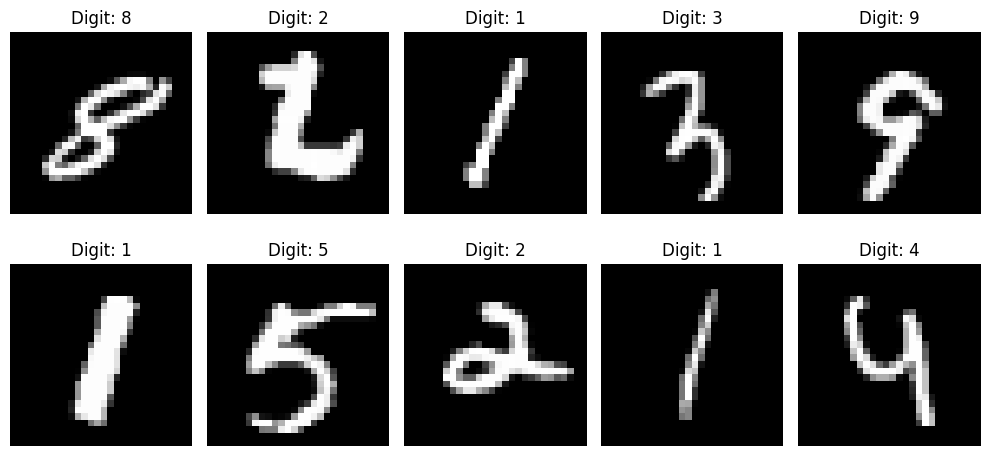

In [ ]:

import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(f"Digit: {labels[i].item()}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import torch
import torch.nn as nn

class MNIST_CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MNIST_CNN().to(device)

print(model)
print("\nDevice:", device)


MNIST_CNN(
  (conv_layers): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Device: cpu


In [ ]:

import torch.optim as optim

loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_function(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = 100 * correct / total

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {average_loss:.4f} | "
        f"Accuracy: {accuracy:.2f}%"
    )


Epoch 1/5 | Loss: 0.2870 | Accuracy: 91.49%
Epoch 2/5 | Loss: 0.0838 | Accuracy: 97.48%
Epoch 3/5 | Loss: 0.0596 | Accuracy: 98.19%
Epoch 4/5 | Loss: 0.0478 | Accuracy: 98.53%
Epoch 5/5 | Loss: 0.0404 | Accuracy: 98.75%


In [ ]:

import time
import json
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

model.eval()

total_loss = 0
correct = 0
total = 0
all_predictions = []
all_labels = []

start_time = time.perf_counter()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = loss_function(outputs, labels)

        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * labels.size(0)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

inference_time = time.perf_counter() - start_time

test_accuracy = 100 * correct / total
test_loss = total_loss / total

print("Test accuracy:", round(test_accuracy, 2), "%")
print("Test loss:", round(test_loss, 4))
print("Correct predictions:", correct, "out of", total)
print("Total evaluation time:", round(inference_time, 3), "seconds")
print(
    "Average time per image:",
    round(inference_time * 1000 / total, 4),
    "milliseconds"
)

print("\nClassification report:")
print(classification_report(all_labels, all_predictions))

matrix = confusion_matrix(all_labels, all_predictions)

print("Confusion matrix:")
print(matrix)

pd.DataFrame(matrix).to_csv(
    "confusion_matrix.csv",
    index=False
)

metrics = {
    "test_accuracy_percent": test_accuracy,
    "test_loss": test_loss,
    "correct_predictions": correct,
    "total_images": total,
    "evaluation_time_seconds": inference_time,
    "average_time_per_image_ms": inference_time * 1000 / total
}

with open("baseline_metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)

torch.save(model.state_dict(), "baseline_model.pth")

print("\nBaseline metrics and model saved successfully.")


Test accuracy: 98.96 %
Test loss: 0.03
Correct predictions: 9896 out of 10000
Total evaluation time: 11.621 seconds
Average time per image: 1.1621 milliseconds

Classification report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       1.00      0.99      1.00      1135
           2       0.99      1.00      0.99      1032
           3       0.99      1.00      0.99      1010
           4       1.00      0.98      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.98      0.99      0.99      1028
           8       0.99      0.98      0.99       974
           9       0.98      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

Confusion matrix:
[[ 978    0    0    0    0    0    0   

## 2. Threat Modeling

### 2.1 System Overview

The app is a handwritten digit classification system implemented with PyTorch and Convolutional Neural Network (CNN). It is based on the MNIST dataset, which consists of 60,000 training images and 10,000 test images. The model tries to predict one of the 10 digits (0-9).

### 2.2 Attacker Model

We assume that an attacker would be able to give the model images and view the predictions that it makes. The attacker is also able to obtain a different copy of the data of MNIST and may be able to train a similar model.

The attacker can either change a part of the training data or can develop carefully altered images, depending on the attack. The attacker does not have administrative access to the system at the start of the attack.

**Attacker goals:**
- Make the model fail to classify handwritten digits.
Use poisoned training data to reduce accuracy of the model.
Take advantage of any gaps in the model's deployment or data-handling.

The following are assumptions made for this application: Attacks will only be carried out on our own model and data-set.

### 2.3 STRIDE Threat Model

STRIDE category | Example mitigation | Possible threat to the CNN |
|---|---|---|
Unauthorized user assumes the identity of a trusted client or training-data source. | Authentication and verification of data sources. |
An attacker alters the labels given to the training set or alters the input images. | Dataset integrity checks, label validation and adversarial training. |
A user rejects images that are submitted as malicious or changes training data. | Timestamped and integrity protected audit logs. |
Restrictions on access to information, output restrictions and testing for privacy. |
Denial of Service | Excessive or frequent requests use up compute resources. | Input limits, rate limiting and resource monitoring. |
Elevating Privilege | Using an vulnerable application or dependency to compromise it. | Least privilege, dependency management, patching.

### 2.4 Mapping to the OWASP Machine Learning Security Top 10

Our experiment has the following risks:

Adversarial images are manipulated to give incorrect predictions. (ML01 – Input Manipulation Attack)
Training samples or labels are tampered in order to affect the behavior of the model. 2. ML02 – Data Poisoning Attack:
The attacker tries to derive information about the training data from access to the model (3. ML03 – Model Inversion Attack).
4. “Membership Inference Attack” – The attacker tries to find out whether a given image was employed in the training process.
ML05 – Model Theft: An intruder tries to obtain a model by asking questions of it and recording the answers it provides.

The main red-team experiments will be on the manipulation of input and data poisoning. The other risks will be outlined as potential risks, not attacks that have been shown to exist.

### 2.5 LINDDUN Privacy Analysis

LINDDUN discovers privacy risks that can occur during the use of machine learning systems for handling personal and sensitive data.

- Linkability: Multiple records pertaining to an individual could be linked based on predictions or logs.
Images or metadata may contain information about an individual if the system relies on identifiable handwriting or related information.
- Non-repudiation: If detailed logs are maintained, they can tie an action to a given user and put up a road block for the user to deny this action.
- **Detectability:** An attacker can tell if someone or any given record exists in the system.
Model outputs can include information about training examples.
Unawareness: Users might not be aware that their images are stored and used for training purposes.
Failure to comply: The collection, storage, or disclosure of personal data without adequate protection could be in violation of relevant privacy obligations.

The MNIST dataset used in this experiment is handwritten digit images and should not contain personal information. But, in real time a handwriting recognition system would be able to process sensitive documents or identifiable handwriting. In a production deployment, therefore, privacy controls would be important.

### 2.6 Initial Security Assessment

The baseline model gives the accuracy of 98.96% on the clean MNIST test set. High accuracy does not mean security from adversarial inputs or poisoned training data. These risks will be assessed using experiments and compared prior to and after the implementation of defensive controls.

In [ ]:

%pip install bandit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.7/134.7 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.0 MB/s eta 0:00:00


In [ ]:

%%writefile mnist_model.py
import torch.nn as nn


class MNIST_CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


Overwriting mnist_model.py


In [ ]:

!bandit -r mnist_model.py -f txt


[main]	INFO	profile include tests: None
[main]	INFO	profile exclude tests: None
[main]	INFO	cli include tests: None
[main]	INFO	cli exclude tests: None
[main]	INFO	running on Python 3.13.16
Run started:2026-10-17 02:49:56.662196+00:00

Test results:
	No issues identified.

Code scanned:
	Total lines of code: 23
	Total lines skipped (#nosec): 0
	Total potential issues skipped due to specifically being disabled (e.g., #nosec BXXX): 0

Run metrics:
	Total issues (by severity):
		Undefined: 0
		Low: 0
		Medium: 0
		High: 0
	Total issues (by confidence):
		Undefined: 0
		Low: 0
		Medium: 0
		High: 0
Files skipped (0):


## 3. Static Application Security Testing (SAST)

### 3.1 Tool Used

**Tool:** Bandit  
The purpose is to check python source code for common security vulnerabilities.

### 3.2 Scan Results

| Metric | Result |
|---|---:|
| Files scanned | 1 |
New lines of code scanned | 23 |
| High-severity issues | 0 |
| Medium-severity issues | 0 |
| Low-severity issues | 0 |
| Total issues identified | 0 |

### 3.3 Findings and Fixes

Bandit did not find any security problems in the implementation of CNN that was scanned. So there was no need to make any code changes because of this scan.

The implementation features a simple CNN architecture with convolutional layers, activation functions, pooling and dropout and fully connected layers.

### 3.4 Limitations

An application that scans clean on Bandit does not mean that the entire application is safe. Bandit primarily targets patterns that can be detected with static analysis, and is not designed to provide resistance against any adversarial examples, training data poisoning, privacy attacks or all types of dependency vulnerabilities.

More testing is needed to assess the security of the model and its data pipeline.

### 3.5 Conclusion

A first scan of the Bandit found no issues in 23 lines of python source code. This is the baseline SAST assessment. As the application and attack pipeline are created, additional security testing will be done.

In [ ]:

print("Model loaded:", isinstance(model, torch.nn.Module))
print("Test images:", len(test_data))
print("Device:", device)

model.eval()


Model loaded: True
Test images: 10000
Device: cpu


MNIST_CNN(
  (conv_layers): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Original predictions: [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]
After attack: [7, 2, 1, 0, 9, 1, 8, 2, 6, 7]


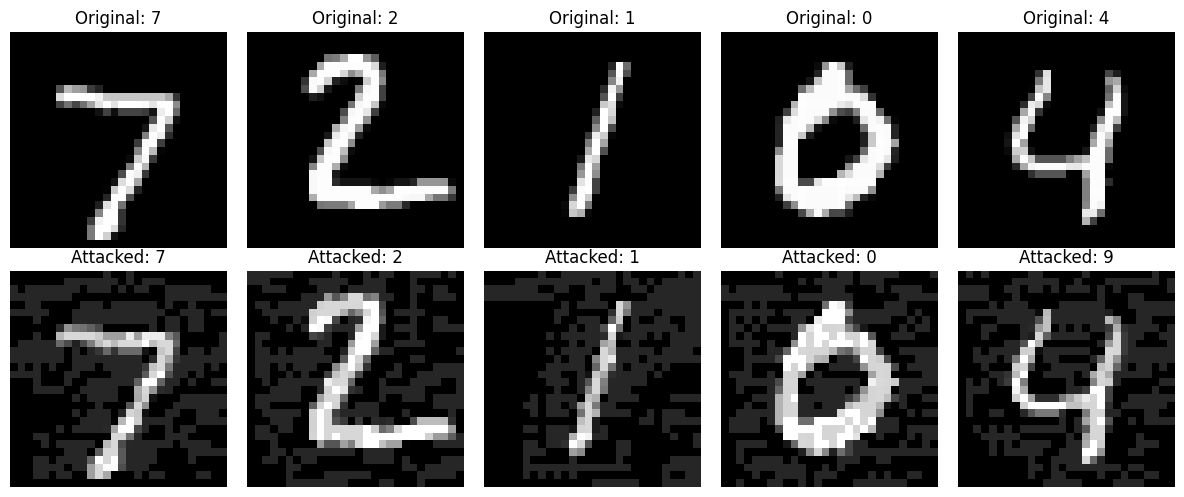

In [ ]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

epsilon = 0.15

model.eval()

def make_adversarial_image(images, labels):
    images = images.clone().detach().to(device)
    labels = labels.to(device)

    images.requires_grad = True

    outputs = model(images)
    loss = F.cross_entropy(outputs, labels)

    model.zero_grad()
    loss.backward()

    changed_images = images + epsilon * images.grad.sign()
    changed_images = torch.clamp(changed_images, 0, 1)

    return changed_images.detach()


# Try the attack on one batch of test images
images, labels = next(iter(test_loader))
images = images[:10].to(device)
labels = labels[:10].to(device)

changed_images = make_adversarial_image(images, labels)

with torch.no_grad():
    original_predictions = model(images).argmax(dim=1)
    changed_predictions = model(changed_images).argmax(dim=1)

print("Original predictions:", original_predictions.cpu().tolist())
print("After attack:", changed_predictions.cpu().tolist())

plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze().cpu(), cmap="gray")
    plt.title(f"Original: {labels[i].item()}")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(changed_images[i].squeeze().cpu(), cmap="gray")
    plt.title(f"Attacked: {changed_predictions[i].item()}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import torch.nn.functional as F

model.eval()

correct = 0
total = 0
attack_success = 0
all_adv_images = []
all_adv_labels = []

for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)

    adv_images = make_adversarial_image(images, labels)

    with torch.no_grad():
        outputs = model(adv_images)
        predictions = outputs.argmax(dim=1)

    correct += (predictions == labels).sum().item()
    attack_success += (predictions != labels).sum().item()
    total += labels.size(0)

    all_adv_images.append(adv_images.cpu())
    all_adv_labels.append(labels.cpu())

adv_accuracy = 100 * correct / total
attack_rate = 100 * attack_success / total

all_adv_images = torch.cat(all_adv_images)
all_adv_labels = torch.cat(all_adv_labels)

print("Clean test accuracy: 98.96%")
print("FGSM test accuracy:", round(adv_accuracy, 2), "%")
print("Misclassified images:", attack_success, "out of", total)
print("Attack success rate:", round(attack_rate, 2), "%")

torch.save(
    {
        "images": all_adv_images,
        "labels": all_adv_labels
    },
    "fgsm_dataset.pth"
)

pd.DataFrame({
    "metric": [
        "Clean accuracy (%)",
        "FGSM accuracy (%)",
        "Misclassified images",
        "Attack success rate (%)"
    ],
    "value": [
        98.96,
        adv_accuracy,
        attack_success,
        attack_rate
    ]
}).to_csv("fgsm_results.csv", index=False)

print("Adversarial dataset saved.")
print("Attack results saved.")


Clean test accuracy: 98.96%
FGSM test accuracy: 72.78 %
Misclassified images: 2722 out of 10000
Attack success rate: 27.22 %
Adversarial dataset saved.
Attack results saved.


The Fast Gradient Sign Method (FGSM) is an example of a red team attack.Fast Gradient Sign Method (FGSM) is an example of a red team attack.

The goal is to assess the sensitivity of the trained CNN with respect to input manipulation.

OWASP ML risk: ML01 – Input Manipulation Attack.

To create adversarial examples, the pixels of the images were perturbed using the FGSM method so as to maximize the loss associated with the classification. The strength of the perturbation was chosen as ε = 0.15 and the values of the pixels were limited to the valid range [0, 1].

**Results:**

| Metric | Result |
|---|---:|
| Clean test accuracy | 98.96% |
| Adversarial test accuracy | 72.78% |
Reduction in accuracy | 26.18 percentage points |
| Misclassified test images | 2,722 / 10,000 |
| Attack success rate | 27.22% |

Observation: Using FGSM generated images caused the model to lose a lot of accuracy. This shows that even if the CNN has many high rates of accuracy on clean input, it is not resistant to adversarial input manipulation.

In [ ]:

import copy
import random
import torch
from torch.utils.data import DataLoader

random.seed(42)
torch.manual_seed(42)

poisoned_data = copy.deepcopy(train_data)
poisoned_data.targets = train_data.targets.clone()

number_to_poison = int(0.10 * len(poisoned_data))
selected_indices = random.sample(
    range(len(poisoned_data)),
    number_to_poison
)

for index in selected_indices:
    old_label = poisoned_data.targets[index].item()

    change = random.randint(1, 9)
    new_label = (old_label + change) % 10

    poisoned_data.targets[index] = new_label

poisoned_loader = DataLoader(
    poisoned_data,
    batch_size=64,
    shuffle=True
)

print("Original training images:", len(train_data))
print("Poisoned training labels:", number_to_poison)
print(
    "Poisoning percentage:",
    round(100 * number_to_poison / len(train_data), 2),
    "%"
)


Original training images: 60000
Poisoned training labels: 6000
Poisoning percentage: 10.0 %


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim

poisoned_model = MNIST_CNN().to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    poisoned_model.parameters(),
    lr=0.001
)

epochs = 5

for epoch in range(epochs):
    poisoned_model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in poisoned_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = poisoned_model(images)
        loss = loss_function(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {total_loss / total:.4f} | "
        f"Accuracy against training labels: "
        f"{100 * correct / total:.2f}%"
    )

torch.save(
    poisoned_model.state_dict(),
    "poisoned_model.pth"
)

print("Poisoned model training completed.")


Epoch 1/5 | Loss: 0.8404 | Accuracy against training labels: 82.21%
Epoch 2/5 | Loss: 0.6836 | Accuracy against training labels: 87.63%
Epoch 3/5 | Loss: 0.6574 | Accuracy against training labels: 88.21%
Epoch 4/5 | Loss: 0.6431 | Accuracy against training labels: 88.58%
Epoch 5/5 | Loss: 0.6295 | Accuracy against training labels: 88.73%
Poisoned model training completed.


In [16]:

poisoned_model.eval()

correct = 0
total = 0
total_loss = 0

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = poisoned_model(images)
        loss = loss_function(outputs, labels)

        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * labels.size(0)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

poisoned_accuracy = 100 * correct / total
poisoned_loss = total_loss / total

print("Baseline clean accuracy: 98.96%")
print("Poisoned model accuracy:", round(poisoned_accuracy, 2), "%")
print("Poisoned model test loss:", round(poisoned_loss, 4))
print("Correct predictions:", correct, "out of", total)
print(
    "Accuracy drop:",
    round(98.96 - poisoned_accuracy, 2),
    "percentage points"
)


Baseline clean accuracy: 98.96%
Poisoned model accuracy: 98.83 %
Poisoned model test loss: 0.1531
Correct predictions: 9883 out of 10000
Accuracy drop: 0.13 percentage points


Training-Data Label Poisoning is a second type of Red-Team Attack.The second type of Red-Team Attack is Training-Data Label Poisoning.

**Objective:** Assess the impact of label noise on CNN classification.

OWASP ML risk: ML02 – Data Poisoning Attack.

Methodology: A new set of MNIST training data was generated. Ten percent of its labels (6,000 out of 60,000) were randomly changed to different digit classes. The dataset was poisoned and a new CNN with the same architecture was trained for five epochs. There is no change in the original test set.

**Results:**

| Metric | Result |
|---|---:|
| Poisoned training samples | 6,000 |
| Poisoning rate | 10% |
Teacher's accuracy | 99.34% |
Poisoned model clean test accuracy | 98.83% |
The average number of percentage points lost in accuracy was 0.13.
| Poisoned model test loss | 0.1531 |

In this experiment, a random label corruption rate of 10% resulted in only a slight drop in the accuracy of the clean tests. The test loss of the model also went up in addition to the accuracy improvement, which shows that the quality of the prediction changes. The results indicate that this kind of poisoning strategy did not significantly decrease the general classification accuracy; other poisoning strategies can have different impacts.

In [17]:

from torch.utils.data import TensorDataset, DataLoader

model.eval()

clean_images = []
clean_labels = []
adv_images_list = []
adv_labels_list = []

# Use a subset to keep training manageable on the CPU
for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)

    changed_images = make_adversarial_image(images, labels)

    clean_images.append(images.cpu())
    clean_labels.append(labels.cpu())
    adv_images_list.append(changed_images.cpu())
    adv_labels_list.append(labels.cpu())

    if sum(batch.shape[0] for batch in clean_images) >= 10000:
        break

clean_images = torch.cat(clean_images)[:10000]
clean_labels = torch.cat(clean_labels)[:10000]
adv_images_list = torch.cat(adv_images_list)[:10000]
adv_labels_list = torch.cat(adv_labels_list)[:10000]

combined_images = torch.cat([clean_images, adv_images_list])
combined_labels = torch.cat([clean_labels, adv_labels_list])

defense_data = TensorDataset(combined_images, combined_labels)

defense_loader = DataLoader(
    defense_data,
    batch_size=64,
    shuffle=True
)

print("Clean training images:", len(clean_images))
print("Adversarial training images:", len(adv_images_list))
print("Combined training images:", len(defense_data))


Clean training images: 10000
Adversarial training images: 10000
Combined training images: 20000


In [18]:

import copy
import torch.optim as optim

# Start from the original trained model
defended_model = copy.deepcopy(model).to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    defended_model.parameters(),
    lr=0.0001
)

epochs = 3

for epoch in range(epochs):
    defended_model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in defense_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = defended_model(images)
        loss = loss_function(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {total_loss / total:.4f} | "
        f"Accuracy: {100 * correct / total:.2f}%"
    )

torch.save(
    defended_model.state_dict(),
    "defended_model.pth"
)

print("Adversarial training completed.")


Epoch 1/3 | Loss: 0.3751 | Accuracy: 88.14%
Epoch 2/3 | Loss: 0.2664 | Accuracy: 91.22%
Epoch 3/3 | Loss: 0.2187 | Accuracy: 92.64%
Adversarial training completed.


In [19]:

defended_model.eval()

clean_correct = 0
adv_correct = 0
total = 0
clean_loss = 0

for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)


    with torch.no_grad():
        clean_outputs = defended_model(images)
        loss = loss_function(clean_outputs, labels)
        clean_predictions = clean_outputs.argmax(dim=1)

    clean_correct += (clean_predictions == labels).sum().item()
    clean_loss += loss.item() * labels.size(0)


    adv_images = make_adversarial_image(images, labels)

    with torch.no_grad():
        adv_outputs = defended_model(adv_images)
        adv_predictions = adv_outputs.argmax(dim=1)

    adv_correct += (adv_predictions == labels).sum().item()
    total += labels.size(0)

clean_accuracy = 100 * clean_correct / total
adv_accuracy = 100 * adv_correct / total
average_loss = clean_loss / total

print("Defended model clean accuracy:", round(clean_accuracy, 2), "%")
print("Defended model FGSM accuracy:", round(adv_accuracy, 2), "%")
print("Defended model clean test loss:", round(average_loss, 4))
print("Clean correct predictions:", clean_correct, "out of", total)
print("Adversarial correct predictions:", adv_correct, "out of", total)


Defended model clean accuracy: 98.82 %
Defended model FGSM accuracy: 87.79 %
Defended model clean test loss: 0.0367
Clean correct predictions: 9882 out of 10000
Adversarial correct predictions: 8779 out of 10000


In [20]:

import torch.nn.functional as F

def smooth_images(images):
    return F.avg_pool2d(
        images,
        kernel_size=3,
        stride=1,
        padding=1
    )


defended_model.eval()

clean_correct = 0
adv_correct = 0
total = 0

for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)

    adv_images = make_adversarial_image(images, labels)

    clean_images = smooth_images(images)
    adv_images = smooth_images(adv_images)

    with torch.no_grad():
        clean_predictions = defended_model(clean_images).argmax(dim=1)
        adv_predictions = defended_model(adv_images).argmax(dim=1)

    clean_correct += (clean_predictions == labels).sum().item()
    adv_correct += (adv_predictions == labels).sum().item()
    total += labels.size(0)

smooth_clean_accuracy = 100 * clean_correct / total
smooth_adv_accuracy = 100 * adv_correct / total

print("Smoothed clean accuracy:", round(smooth_clean_accuracy, 2), "%")
print("Smoothed FGSM accuracy:", round(smooth_adv_accuracy, 2), "%")
print("Clean correct:", clean_correct, "out of", total)
print("Adversarial correct:", adv_correct, "out of", total)


Smoothed clean accuracy: 98.12 %
Smoothed FGSM accuracy: 91.28 %
Clean correct: 9812 out of 10000
Adversarial correct: 9128 out of 10000


In [21]:

import pandas as pd

results = {
    "Experiment": [
        "Baseline CNN",
        "FGSM Attack",
        "Label Poisoning",
        "Adversarial Training",
        "Adversarial Training + Smoothing"
    ],
    "Clean Accuracy (%)": [
        98.96,
        None,
        98.83,
        98.82,
        98.12
    ],
    "Adversarial Accuracy (%)": [
        None,
        72.78,
        None,
        87.79,
        91.28
    ],
    "Test Loss": [
        0.0300,
        None,
        0.1531,
        0.0367,
        None
    ]
}

results_table = pd.DataFrame(results)

display(results_table)

results_table.to_csv(
    "final_performance_comparison.csv",
    index=False
)

print("Comparison table saved successfully.")


,Experiment,Clean Accuracy (%),Adversarial Accuracy (%),Test Loss
0,Baseline CNN,98.96,NaN,0.0300
1,FGSM Attack,NaN,72.78,NaN
2,Label Poisoning,98.83,NaN,0.1531
3,Adversarial Training,98.82,87.79,0.0367
4,Adversarial Training + Smoothing,98.12,91.28,NaN


Comparison table saved successfully.


In [22]:

import pandas as pd

results = [
    {
        "Experiment": "Baseline CNN",
        "Clean Accuracy (%)": 98.96,
        "Adversarial Accuracy (%)": None,
        "Test Loss": 0.0300
    },
    {
        "Experiment": "FGSM Attack",
        "Clean Accuracy (%)": None,
        "Adversarial Accuracy (%)": 72.78,
        "Test Loss": None
    },
    {
        "Experiment": "Label Poisoning",
        "Clean Accuracy (%)": 98.83,
        "Adversarial Accuracy (%)": None,
        "Test Loss": 0.1531
    },
    {
        "Experiment": "Adversarial Training",
        "Clean Accuracy (%)": 98.82,
        "Adversarial Accuracy (%)": 87.79,
        "Test Loss": 0.0367
    },
    {
        "Experiment": "Adversarial Training + Smoothing",
        "Clean Accuracy (%)": 98.12,
        "Adversarial Accuracy (%)": 91.28,
        "Test Loss": None
    }
]

results_table = pd.DataFrame(results)

display(results_table)

results_table.to_csv(
    "final_performance_comparison.csv",
    index=False
)

print("Corrected comparison table saved.")


,Experiment,Clean Accuracy (%),Adversarial Accuracy (%),Test Loss
0,Baseline CNN,98.96,NaN,0.0300
1,FGSM Attack,NaN,72.78,NaN
2,Label Poisoning,98.83,NaN,0.1531
3,Adversarial Training,98.82,87.79,0.0367
4,Adversarial Training + Smoothing,98.12,91.28,NaN


Corrected comparison table saved.


In [23]:

import pandas as pd

results_table = pd.DataFrame([
    ["Baseline CNN", 98.96, None, 0.0300],
    ["FGSM Attack", None, 72.78, None],
    ["Label Poisoning", 98.83, None, 0.1531],
    ["Adversarial Training", 98.82, 87.79, 0.0367],
    ["Adversarial Training + Smoothing", 98.12, 91.28, None]
], columns=[
    "Experiment",
    "Clean Accuracy (%)",
    "Adversarial Accuracy (%)",
    "Test Loss"
])

display(results_table)

results_table.to_csv(
    "final_performance_comparison.csv",
    index=False
)

print("Final comparison saved successfully.")


,Experiment,Clean Accuracy (%),Adversarial Accuracy (%),Test Loss
0,Baseline CNN,98.96,NaN,0.0300
1,FGSM Attack,NaN,72.78,NaN
2,Label Poisoning,98.83,NaN,0.1531
3,Adversarial Training,98.82,87.79,0.0367
4,Adversarial Training + Smoothing,98.12,91.28,NaN


Final comparison saved successfully.


In [24]:

from IPython.display import display, HTML

display(HTML("""
<table style="border-collapse:collapse; width:100%; text-align:center;">
<tr>
<th style="border:1px solid;padding:8px">Experiment</th>
<th style="border:1px solid;padding:8px">Clean Accuracy (%)</th>
<th style="border:1px solid;padding:8px">Adversarial Accuracy (%)</th>
<th style="border:1px solid;padding:8px">Test Loss</th>
</tr>
<tr><td style="border:1px solid;padding:8px">Baseline CNN</td><td>98.96</td><td>—</td><td>0.0300</td></tr>
<tr><td style="border:1px solid;padding:8px">FGSM Attack</td><td>—</td><td>72.78</td><td>—</td></tr>
<tr><td style="border:1px solid;padding:8px">Label Poisoning</td><td>98.83</td><td>—</td><td>0.1531</td></tr>
<tr><td style="border:1px solid;padding:8px">Adversarial Training</td><td>98.82</td><td>87.79</td><td>0.0367</td></tr>
<tr><td style="border:1px solid;padding:8px">Training + Smoothing</td><td>98.12</td><td>91.28</td><td>—</td></tr>
</table>
"""))


Experiment,Clean Accuracy (%),Adversarial Accuracy (%),Test Loss
Baseline CNN,98.96,—,0.0300
FGSM Attack,—,72.78,—
Label Poisoning,98.83,—,0.1531
Adversarial Training,98.82,87.79,0.0367
Training + Smoothing,98.12,91.28,—
